# Modellierung

## Init

In [88]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor
from sklearn.neural_network import MLPRegressor

# Load the dataset
file_path = '../../data/processed/sickness_table.csv'
df = pd.read_csv(file_path, index_col=0)

# Convert date column to datetime
df['date'] = pd.to_datetime(df['date'])

# Datenselektierung

In [89]:
df

,date,n_sick,calls,n_duty,n_sby,sby_need,dafted,is_holiday,month,day_of_week,...,is_weekend,unix_ts_date,calls_per_duty,call_stress,sby_used_percent,calls_ma_7,n_sick_ma_7,calls_ma_7_lag_30,n_sick_ma_7_lag_30,season
0,2016-04-01,73,8154.0,1700,90,4.0,0.0,False,4,4,...,False,1459468800,4.796471,4.785211,4.444444,0.000000,0.000000,0.000000,0.000000,1
1,2016-04-02,64,8526.0,1700,90,70.0,0.0,False,4,5,...,True,1459555200,5.015294,4.816949,77.777778,0.000000,0.000000,0.000000,0.000000,1
2,2016-04-03,68,8088.0,1700,90,0.0,0.0,False,4,6,...,True,1459641600,4.757647,4.757647,0.000000,0.000000,0.000000,0.000000,0.000000,1
3,2016-04-04,71,7044.0,1700,90,0.0,0.0,False,4,0,...,False,1459728000,4.143529,4.143529,0.000000,0.000000,0.000000,0.000000,0.000000,1
4,2016-04-05,63,7236.0,1700,90,0.0,0.0,False,4,1,...,False,1459814400,4.256471,4.256471,0.000000,0.000000,0.000000,0.000000,0.000000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1147,2019-05-23,86,8544.0,1900,90,0.0,0.0,False,5,3,...,False,1558569600,4.496842,4.496842,0.000000,9060.000000,78.571429,9396.857143,80.000000,1
1148,2019-05-24,81,8814.0,1900,90,0.0,0.0,False,5,4,...,False,1558656000,4.638947,4.638947,0.000000,9063.428571,77.571429,9628.285714,82.571429,1
1149,2019-05-25,76,9846.0,1900,90,146.0,56.0,False,5,5,...,True,1558742400,5.182105,4.812317,162.222222,8966.571429,78.142857,9534.000000,82.714286,1
1150,2019-05-26,83,9882.0,1900,90,160.0,70.0,False,5,6,...,True,1558828800,5.201053,4.797087,177.777778,9190.285714,78.857143,9422.571429,82.571429,1


In [90]:

# List der Spalten, die nicht benutzt werden sollen, da sie u. a. zur Anwendungszeit nicht zur Verfügung stehen und daher auch nicht als Features genutzt werden können oder
excluded_columns = ["sby_need", "dafted", "n_sick", "calls", "call_stress", "sby_used_percent", "calls_per_duty", "date", "calls_ma_7", "n_sick_ma_7", "unix_ts_date"]

usable_columns = list(set(df.columns) - set(excluded_columns))

target_column = 'calls'

print(usable_columns)

['n_sby', 'week_of_year', 'season', 'is_weekend', 'n_sick_ma_7_lag_30', 'day_of_week', 'month', 'n_duty', 'is_holiday', 'calls_ma_7_lag_30']


In [91]:
# Prepare features and target
X = df[usable_columns]

#X = df[['n_duty', 'season', 'month', 'day_of_week', 'is_holiday', 'is_weekend']] #auf faktoren beschränkt, die man zu dem Zeitpunkt der Planung wissen kann

y = df[target_column]

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Modellierungvergleiche

In [92]:

# Initialize models
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'Support Vector Machine': SVR(),
    'K-Nearest Neighbors': KNeighborsRegressor(),
    'Neural Network': MLPRegressor(random_state=42, max_iter=1000),
    'Lasso Regression': Lasso(random_state=42),
    'Ridge Regression': Ridge(random_state=42),
    'XGBoost': XGBRegressor(random_state=42)
}

# Train and evaluate each model
results = {}
for model_name, model in models.items():
    start_time = time.time()
    model.fit(X_train, y_train)
    end_time = time.time() 

    training_time = end_time - start_time
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    results[model_name] = {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2, "Training Time" : training_time}
    print(f'{model_name} - MAE: {mae}, MSE: {mse}, RMSE: {rmse}, R2: {r2}, "Training Time (s)" : {training_time}')


Linear Regression - MAE: 778.3001517322897, MSE: 915296.5305499721, RMSE: 956.7113099310429, R2: 0.4068971459052345, "Training Time (s)" : 0.003603219985961914
Decision Tree - MAE: 1076.8051948051948, MSE: 1692418.7532467532, RMSE: 1300.9299570871422, R2: -0.09667016029331599, "Training Time (s)" : 0.006061077117919922
Random Forest - MAE: 743.3036363636364, MSE: 836527.6223220779, RMSE: 914.6188399120575, R2: 0.45793859829205974, "Training Time (s)" : 0.30080723762512207
Gradient Boosting - MAE: 752.8599277720556, MSE: 826142.9919766911, RMSE: 908.9240848259502, R2: 0.46466773326744004, "Training Time (s)" : 0.09682416915893555
Support Vector Machine - MAE: 1005.1803588455275, MSE: 1561228.5290007477, RMSE: 1249.4913080933168, R2: -0.011660227629324504, "Training Time (s)" : 0.026495695114135742
K-Nearest Neighbors - MAE: 866.0519480519481, MSE: 1166958.102857143, RMSE: 1080.258350052034, R2: 0.24382300346128483, "Training Time (s)" : 0.0011887550354003906
Neural Network - MAE: 784.21

Models sorted by MAE:


,MAE,MSE,RMSE,R2,Training Time
Random Forest,743.303636,8.365276e+05,914.618840,0.457939,0.300807
Gradient Boosting,752.859928,8.261430e+05,908.924085,0.464668,0.096824
Lasso Regression,778.058640,9.137223e+05,955.888238,0.407917,0.009179
Ridge Regression,778.217072,9.148953e+05,956.501593,0.407157,0.001164
Linear Regression,778.300152,9.152965e+05,956.711310,0.406897,0.003603
Neural Network,784.216405,9.065311e+05,952.119242,0.412577,1.134482
XGBoost,845.618802,1.108879e+06,1053.033048,0.281458,0.043411
K-Nearest Neighbors,866.051948,1.166958e+06,1080.258350,0.243823,0.001189
Support Vector Machine,1005.180359,1.561229e+06,1249.491308,-0.011660,0.026496
Decision Tree,1076.805195,1.692419e+06,1300.929957,-0.096670,0.006061


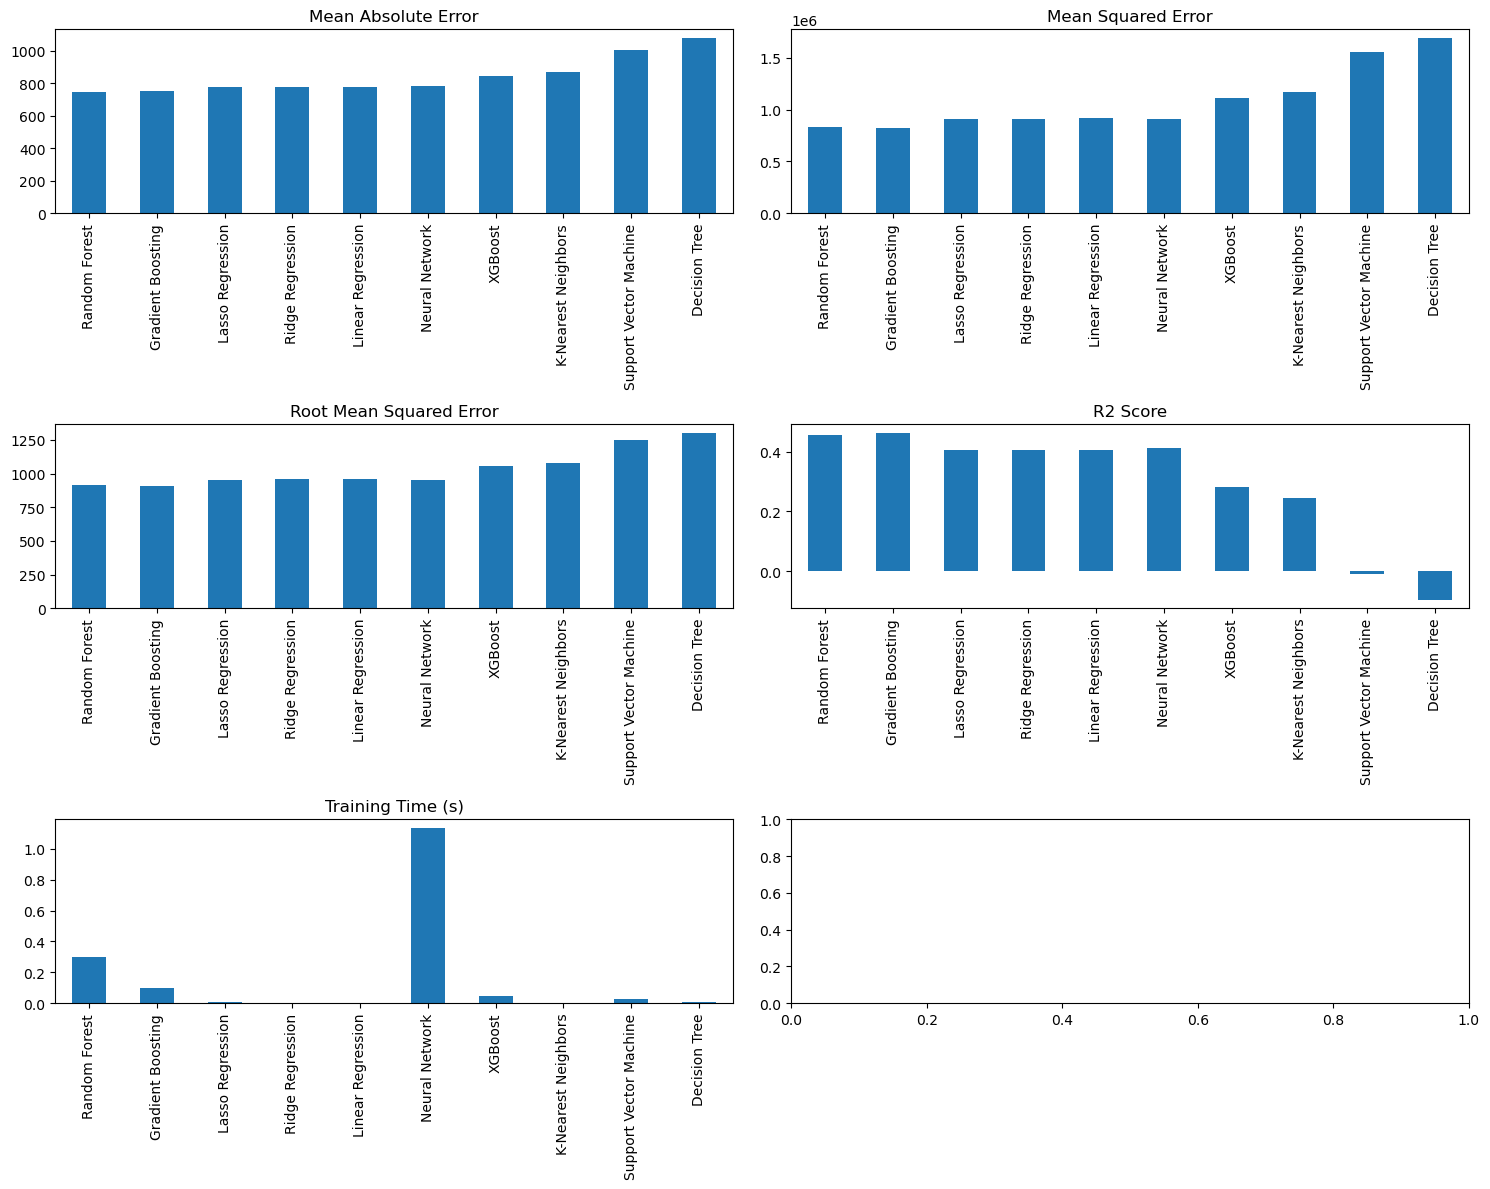

In [93]:
# Convert results to a DataFrame for easier comparison
results_df = pd.DataFrame(results).T

# Sort the models by MAE (you can change the metric to sort by other scores)
results_df_sorted = results_df.sort_values(by='MAE')

print("Models sorted by MAE:")
display(results_df_sorted)

# Visualize the results
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
results_df_sorted['MAE'].plot(kind='bar', ax=axes[0, 0], title='Mean Absolute Error')
results_df_sorted['MSE'].plot(kind='bar', ax=axes[0, 1], title='Mean Squared Error')
results_df_sorted['RMSE'].plot(kind='bar', ax=axes[1, 0], title='Root Mean Squared Error')
results_df_sorted['R2'].plot(kind='bar', ax=axes[1, 1], title='R2 Score')
results_df_sorted['Training Time'].plot(kind='bar', ax=axes[2, 0], title='Training Time (s)')
plt.tight_layout()
plt.show()

In [94]:
# Select the best model based on MAE
best_model_name = results_df_sorted.index[0]
best_model_results = results_df_sorted.loc[best_model_name]

print(f'Best Model: {best_model_name}')
print(best_model_results)

Best Model: Random Forest
MAE                 743.303636
MSE              836527.622322
RMSE                914.618840
R2                    0.457939
Training Time         0.300807
Name: Random Forest, dtype: float64


Final Evaluation of the Best Model (Random Forest):
MAE: 740.2858371242754, MSE: 837150.6904608881, RMSE: 914.9593927934114, R2: 0.4575348564673182


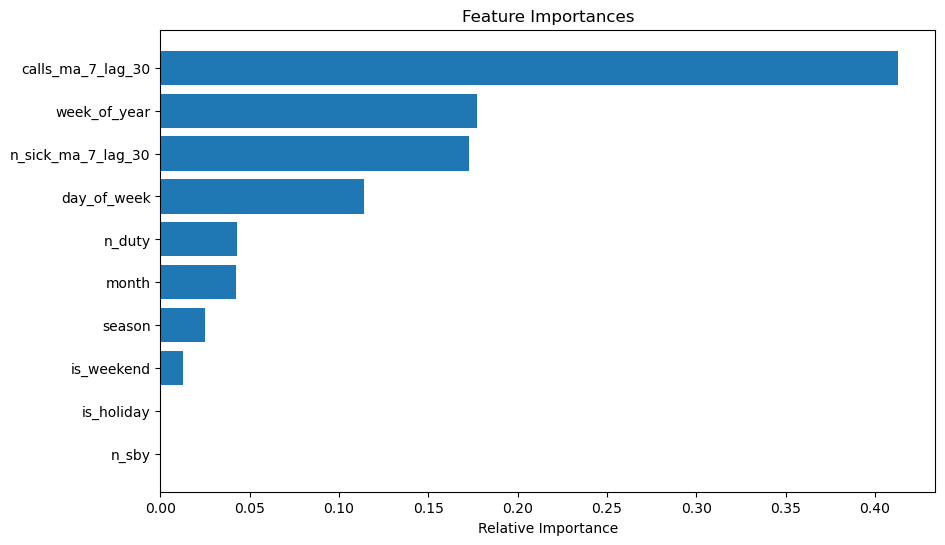

In [95]:
# If further fine-tuning is needed, you can perform hyperparameter tuning on the best model
if best_model_name == 'Random Forest':
    param_grid = {
        'n_estimators': [100, 200],
        'max_depth': [10, 20, None],
        'min_samples_split': [2, 5]
    }
    grid_search = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=5, scoring='neg_mean_absolute_error')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
elif best_model_name == 'Gradient Boosting':
    param_grid = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7]
    }
    grid_search = GridSearchCV(GradientBoostingRegressor(random_state=42), param_grid, cv=5, scoring='neg_mean_absolute_error')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
elif best_model_name == 'XGBoost':
    param_grid = {
        'n_estimators': [100, 200],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7]
    }
    grid_search = GridSearchCV(XGBRegressor(random_state=42), param_grid, cv=5, scoring='neg_mean_absolute_error')
    grid_search.fit(X_train, y_train)
    best_model = grid_search.best_estimator_
# Add similar tuning for other models if needed

# Train the best model with the entire dataset
best_model.fit(X_train, y_train)
y_pred_best = best_model.predict(X_test)

# Final evaluation of the best model
final_mae = mean_absolute_error(y_test, y_pred_best)
final_mse = mean_squared_error(y_test, y_pred_best)
final_rmse = np.sqrt(final_mse)
final_r2 = r2_score(y_test, y_pred_best)

print(f'Final Evaluation of the Best Model ({best_model_name}):')
print(f'MAE: {final_mae}, MSE: {final_mse}, RMSE: {final_rmse}, R2: {final_r2}')


# Feature Importance for the best model
importances = best_model.feature_importances_
features = X.columns
indices = np.argsort(importances)

plt.figure(figsize=(10, 6))
plt.title('Feature Importances')
plt.barh(range(len(indices)), importances[indices], align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance')
plt.show()


In [106]:
top_5_features = [features[i] for i in indices][5:]

top_5_features.reverse()

display(top_5_features)

['calls_ma_7_lag_30',
 'week_of_year',
 'n_sick_ma_7_lag_30',
 'day_of_week',
 'n_duty']

# Modell mit weniger Features (nur die wichtigsten)

In [107]:
best_model = grid_search.best_estimator_

best_model.fit(X_train, y_train)

X = df[top_5_features]
y = df[target_column]

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

best_model.fit(X_train, y_train)

RandomForestRegressor(max_depth=20, n_estimators=200, random_state=42)

# Prediction Test

In [108]:
predict_data = pd.DataFrame([{
        'unix_ts_date' : 1723704690, 
        'month' : 4,
        'day_of_week' : 4,
        'is_weekend' : False

    }])


best_model.predict(predict_data)

ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- is_weekend
- month
- unix_ts_date
Feature names seen at fit time, yet now missing:
- calls_ma_7_lag_30
- n_duty
- n_sick_ma_7_lag_30
- week_of_year


# Export model

In [109]:
import joblib

# Modell speichern
joblib.dump(best_model, '../../app/models/readiness_model.pkl')

['../../app/models/readiness_model.pkl']